# Sensitivity of the FLORIS Wake Model on the Lillgrund Wind Farm

__Maarten T. van Beek__, Department of Wind Energy, Faculty of Aerospace Engineering, Delft University of Technology, Delft, The Netherlands

__Axelle Viré__, Department of Wind Energy, Faculty of Aerospace Engineering, Delft University of Technology, Delft, The Netherlands

__Søren J. Andersen__, Department of Wind Energy, Technological University of Denmark, Kgs. Lyngby, Denmark

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes a few seconds.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import lillgrund_model as lm

SEED = 2021                       # the only seed in this notebook (also the seed of generate_data.py)
t_start = time.perf_counter()
labels = [r'$\alpha$', r'$\beta$', r'$k_a$', r'$k_b$', r'$a_d$', r'$b_d$']

### Summary

van Beek, Viré and Andersen [[1]](https://doi.org/10.3390/en14051293) calibrate the six wake parameters of the FLORIS Gauss-Curl Hybrid model (near-wake length $\alpha, \beta$; wake expansion $k_a, k_b$; natural deflection $a_d, b_d$) against SCADA data from the 48-turbine Lillgrund offshore wind farm, and use Sobol indices to find that $k_a$, $b_d$ and $\alpha$ dominate and $a_d$ is negligible. We run the same FLORIS 2.0.1 model (ported to numpy and checked against FLORIS to rounding error) on a public Lillgrund layout with a generic turbine curve, sample the six parameters uniformly on the paper's bounds, and compute the active subspace of the total farm power at 8 m/s with wind from 180° (turbines in lines 4.8 D apart along the wind), from 500 samples with finite-difference gradients. The farm power has a three-dimensional active subspace (an eigenvalue ratio of 156 after the third eigenvalue): a combination led by $\alpha$, one led by $k_a$, and $b_d$; a cubic in the three active variables has leave-one-out $R^2 = 0.975$, while $k_b$, $a_d$ and a contrast of $\alpha$ and $\beta$ that leaves the near-wake length nearly unchanged are inactive.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

van Beek et al. [[1]](https://doi.org/10.3390/en14051293) use FLORIS 2.0.1 [[2]](https://github.com/NREL/floris) in its Gauss-Curl Hybrid (GCH) configuration (Sec. 2.2). FLORIS sweeps the turbines from upstream to downstream; each turbine's rotor-averaged speed $\bar U$ (the cube root of the mean cube over the 9 grid points inside its disk) gives its thrust coefficient $C_T$ and power $P = \tfrac12\rho A C_p(\bar U)\bar U^3$, and its wake is added to the flow seen by the turbines behind it. At zero yaw, with $I$ the turbulence intensity at the rotor, the near wake ends at (Eq. 1)

$$
\frac{x_0}{D} = \frac{1+\sqrt{1-C_T}}{\sqrt2\,\bigl(4\alpha I + 2\beta\,(1-\sqrt{1-C_T})\bigr)},
$$

and beyond it the velocity deficit is Gaussian (Eq. 2, after Bastankhah and Porté-Agel [[3]](https://doi.org/10.1017/jfm.2016.595)),

$$
\frac{U}{U_\infty} = 1-\Bigl(1-\sqrt{1-\tfrac{\sigma_{y0}\sigma_{z0}}{\sigma_y\sigma_z}C_T}\Bigr)\exp\Bigl(-\frac{(y-\delta_f)^2}{2\sigma_y^2}-\frac{z^2}{2\sigma_z^2}\Bigr),\qquad
\sigma_{y,z} = \sigma_{y0,z0} + k\,(x-x_0),\quad k = k_a I + k_b
$$

(Eqs. 7–9), with the width interpolated linearly between the rotor and $x_0$. The wake centre is displaced by $\delta_f$, which contains the natural deflection $a_d + b_d\,x$ (Eq. 10) and the deflection from an "effective yaw" angle (Eqs. 3–4). The GCH additions (Sec. 2.2.3, King et al. [[4]](https://doi.org/10.5194/wes-6-701-2021)) are the lateral and vertical velocities of the wake-rotation vortices (core size $e = 0.2D$), which add wake recovery (Eq. 11, $\alpha_r = 0.03$) and set each turbine's effective yaw ("secondary steering"). Added turbulence follows Crespo and Hernández [[5]](https://doi.org/10.1016/0167-6105(95)00033-X), and wakes combine by sum of squares. The six inputs are $\boldsymbol\Psi = (\alpha, \beta, k_a, k_b, a_d, b_d)$, independent and uniform on the bounds of the paper's Table 2 (p. 7), which the paper uses both for calibration and for its Sobol study (Sec. 3.1).

**Implementation.** `lillgrund_model.py` is a numpy port of FLORIS 2.0.1 for this configuration at zero yaw; it reproduces FLORIS 2.0.1 to rounding error (differences below $10^{-15}$ of the largest turbine power; `DATA.md`). Three features of FLORIS 2.0.1 matter here:

- $a_d$ enters in **metres** (FLORIS adds `ad + bd*(x - x_turbine)`), not as $a_d D$ as Eq. 10 writes it, so over its range $[-1, 1]$ it moves the wakes by at most 1 m. This explains the paper's finding that $a_d$ is negligible.
- The effective yaw of secondary steering is the integer angle in $[-30°, 30°]$ that best matches the circulation seen at the rotor, and the added turbulence uses a count of rotor points with a deficit of at most 0.05 m/s. Both are discrete, so the farm power is piecewise smooth, with small jumps. The gradients are those of the smooth piece (differences with the discrete choices frozen).
- Even at zero yaw, waked turbines get effective yaw angles of several degrees from the wake-rotation vortices of the turbines upstream, so the wakes deflect.

**Set-up.** The SCADA data, wind rose and empirical power curve of the paper are under a non-disclosure agreement. We use the turbine positions and the generic Siemens SWT-2.3-93 power and thrust curves of PyWake's Lillgrund example [[6]](https://gitlab.windenergy.dtu.dk/TOPFARM/PyWake), the paper's $D = 92.6$ m and hub height 65 m, and the settings of FLORIS 2.0.1's example input for what the paper does not state (ambient TI 0.06, shear exponent 0.12, Crespo-Hernández constants). The quantity of interest is the **total power of the 48 turbines at 8 m/s with wind from 180°**, the case of the paper's Fig. 6, where the turbines stand in rows 4.8 D apart along the wind (Table 1). The data also hold the farm power at one alignment direction of each other spacing of Table 1 (3.3, 4.3, 5.9, 7.1 and 8.6 D). The paper's Sobol output is the annual energy production over its wind rose, so its indices are not directly comparable (see the comparison below).

The cell prints the inputs and settings from `lillgrund_model.py`.

In [2]:
print(f"{'input':6s} {'units':5s} {'lower':>7s} {'upper':>7s} {'FLORIS default':>14s}  description")
for j, n in enumerate(lm.NAMES):
    print(f'{n:6s} {lm.UNITS[j]:5s} {lm.LOWER[j]:7.3f} {lm.UPPER[j]:7.3f} {lm.NOMINAL[j]:14.3f}  {lm.DESCRIPTIONS[j]}')
print(f'\nturbine: D = {lm.D} m, hub height {lm.HUB_HEIGHT} m, TSR {lm.TSR}; {lm.N_TURBINES} turbines')
print(f'inflow: U = {lm.WS} m/s at hub height, TI = {lm.TI}, shear exponent {lm.SHEAR}, rho = {lm.RHO} kg/m^3')
print(f'GCH settings: e = {lm.EPS_GAIN} D, alpha_r = {lm.YAW_RECOVERY_ALPHA}; Crespo-Hernandez '
      f'(initial, constant, ai, downstream) = {lm.CRESPO_HERNANDEZ}')
P_free = lm.N_TURBINES*lm.free_power()
P_nom = lm.farm_power(lm.NOMINAL)
print(f'\nlone turbine at 8 m/s: {lm.free_power()/1e3:.1f} kW; 48 of them: {P_free/1e6:.2f} MW')
print(f'farm power at the FLORIS defaults, wind from 180 deg: {P_nom/1e6:.3f} MW '
      f'(farm efficiency {P_nom/P_free:.3f})')

input  units   lower   upper FLORIS default  description
alpha  -       0.125   2.500          0.580  near-wake length: turbulence weight (Eq. 1)
beta   -       0.015   0.300          0.077  near-wake length: thrust weight (Eq. 1)
ka     -       0.050   1.500          0.380  wake expansion: turbulence-intensity weight, k = ka*I + kb (Eq. 9)
kb     -       0.000   0.020          0.004  wake expansion: base rate (Eq. 9)
ad     m      -1.000   1.000          0.000  natural wake deflection: offset (Eq. 10; metres in FLORIS)
bd     -      -0.100   0.100          0.000  natural wake deflection: slope per metre downstream (Eq. 10)

turbine: D = 92.6 m, hub height 65.0 m, TSR 8.0; 48 turbines
inflow: U = 8.0 m/s at hub height, TI = 0.06, shear exponent 0.12, rho = 1.225 kg/m^3
GCH settings: e = 0.2 D, alpha_r = 0.03; Crespo-Hernandez (initial, constant, ai, downstream) = (0.5, 0.9, 0.75, -0.325)

lone turbine at 8 m/s: 896.1 kW; 48 of them: 43.01 MW
farm power at the FLORIS defaults, wind from

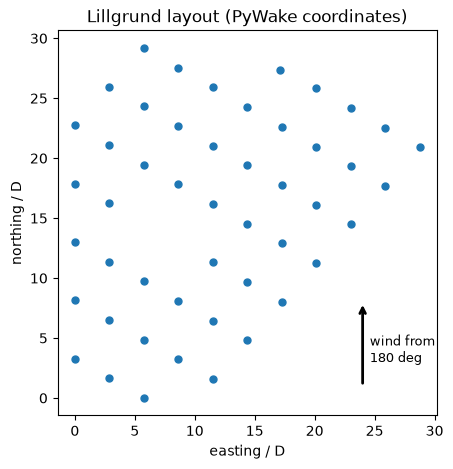

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(lm.LAYOUT_X/lm.D, lm.LAYOUT_Y/lm.D, 'o', ms=5)
ax.annotate('', xy=(24, 8), xytext=(24, 1), arrowprops=dict(arrowstyle='->', lw=2))
ax.text(24.6, 3, 'wind from\n180 deg', fontsize=9)
ax.set_xlabel('easting / D'); ax.set_ylabel('northing / D'); ax.set_aspect('equal')
ax.set_title('Lillgrund layout (PyWake coordinates)')
plt.close(fig)
fig

The farm is a skewed grid, with turbines 3.3 D apart within a row and rows 4.3 D apart (Table 1 of the paper), and two positions empty in the middle. With wind from 180° the turbines stand in north-south lines 4.8 D apart, so most turbines are in the wakes of the ones in front; at the FLORIS defaults the farm produces 18.4 MW, 43 % of what 48 lone turbines would.

### Load data

`generate_data.py` drew $M = 500$ samples of the six parameters, independent and uniform on the bounds of Table 2 (seed 2021), and wrote the farm power at 8 m/s for the six alignment directions of the paper's Table 1, with its gradient with respect to the physical parameters (see `DATA.md`). The main case is wind from 180°.

In [4]:
X = np.loadtxt('inputs.csv', delimiter=',')                     # (M, 6) physical parameters
F = np.loadtxt('outputs.csv', delimiter=',')                    # (M, 6) farm power, MW, six directions
G = np.loadtxt('gradients.csv', delimiter=',').reshape(len(X), len(lm.DIRECTIONS), 6)  # MW per unit
k180 = lm.DIRECTIONS.index(180.0)
f, df = F[:, k180], G[:, k180, :]                               # the main case: wind from 180 deg
print(f'inputs {X.shape}, outputs {F.shape}, gradients {G.shape}; main case: column {k180} (180 deg)')

inputs (500, 6), outputs (500, 6), gradients (500, 6, 6); main case: column 2 (180 deg)


We re-solve three samples with `lillgrund_model.py` and compare with `outputs.csv`, and check the shipped gradients (central differences with FLORIS's discrete choices frozen, step $10^{-4}$ of each half-range) against plain central differences with step $10^{-6}$, nothing frozen, at two samples.

In [5]:
rows = [0, 1, 2]
f_new = np.array([lm.farm_power(X[i], 180.0)/1e6 for i in rows])
print(f'max |model - outputs.csv| / P = {np.max(np.abs(f_new - f[rows])/f[rows]):.1e}')
half = (lm.UPPER - lm.LOWER)/2
for i in rows[:2]:
    g_fd = np.array([(lm.farm_power(X[i] + 1e-6*half*e, 180.0) - lm.farm_power(X[i] - 1e-6*half*e, 180.0))
                     / (2e-6*half @ e)/1e6 for e in np.eye(6)])
    print(f'row {i}: gradients.csv vs plain central differences (step 1e-6 of the half-range): '
          f'relative error {np.linalg.norm(g_fd - df[i])/np.linalg.norm(df[i]):.1e}')
print(f'P(180 deg): mean {f.mean():.3f} MW, std {f.std(ddof=1):.3f} MW, range [{f.min():.2f}, {f.max():.2f}] MW')

max |model - outputs.csv| / P = 1.6e-16


row 0: gradients.csv vs plain central differences (step 1e-6 of the half-range): relative error 3.1e-09


row 1: gradients.csv vs plain central differences (step 1e-6 of the half-range): relative error 2.5e-09
P(180 deg): mean 28.211 MW, std 4.948 MW, range [13.29, 35.58] MW


### Estimate the subspace

The model gives gradients (central differences of the farm solve with FLORIS's discrete choices frozen, accurate to about $10^{-8}$), so we use the gradient estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates. The input space is `ac.Uniform` on the Table 2 bounds; we pass the physical samples and the physical gradients, and the library maps both to $[-1,1]^6$ once (the normalized gradient is the physical one times the half-ranges). We use 500 bootstrap replicates and compare the library's dimension rule with the eigenvalue ratios.

In [6]:
space = ac.Uniform(lm.LOWER, lm.UPPER, names=list(lm.NAMES))
sub = ac.active_subspace(space=space, X=X, f=f, grads=df, estimator='as', nboot=500, rng=SEED)
lam = sub.eigenvalues
ks, crit, k_hat = ac.dimension_criterion(sub, rule='evg')
print('eigenvalues:', np.array2string(lam, precision=4))
print(f'eigenvalue-gap rule (largest difference lambda_k - lambda_k+1) picks n = {k_hat}; '
      f'ratios lambda_k/lambda_k+1:', np.array2string(lam[:-1]/lam[1:], precision=2))
sub3 = ac.with_dimension(sub, 3)       # the largest ratio is at k = 3 (see the text)

eigenvalues: [1.1311e+02 4.6669e+01 4.4545e+01 2.8531e-01 2.2271e-03 1.9672e-04]
eigenvalue-gap rule (largest difference lambda_k - lambda_k+1) picks n = 1; ratios lambda_k/lambda_k+1: [  2.42   1.05 156.13 128.11  11.32]


### Results

**Eigenvalues.** The figure shows the eigenvalues with a 95 % bootstrap band.

95% bootstrap intervals: [89.4, 146], [42.9, 53.5], [36.7, 46.9], [0.12, 0.528], [0.00173, 0.00276], [0.000145, 0.00024]


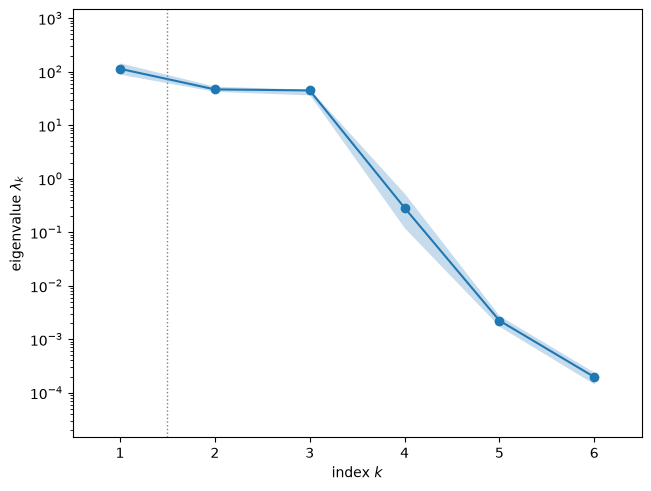

In [7]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
plt.close(fig)
lo, hi = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('95% bootstrap intervals:', ', '.join(f'[{a:.3g}, {b:.3g}]' for a, b in zip(lo, hi)))
fig

The eigenvalues fall in two groups: $\lambda_1 = 113.1$, $\lambda_2 = 46.67$ and $\lambda_3 = 44.55$, then $\lambda_4 = 0.285$, $\lambda_5 = 2.2\times10^{-3}$ and $\lambda_6 = 2.0\times10^{-4}$. The ratio $\lambda_3/\lambda_4 = 156$ is the clear gap, and the bootstrap intervals of $\lambda_3$ ([36.7, 46.9]) and $\lambda_4$ ([0.12, 0.528]) are two orders of magnitude apart. The library's eigenvalue-gap rule, which uses differences $\lambda_k - \lambda_{k+1}$, picks $n = 1$ ($\lambda_1/\lambda_2 = 2.42$ only), so we set $n = 3$ by hand.

bootstrap mean subspace distance, k = 1..5: [0.093 0.546 0.01  0.004 0.017]


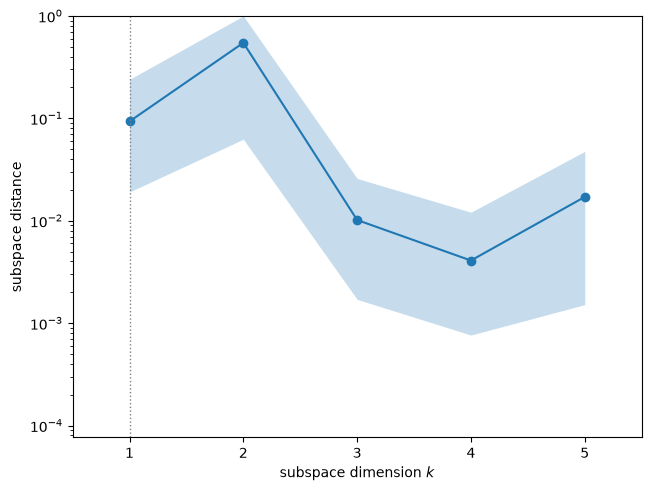

In [8]:
fig, ax = ac.plotting.plot_subspace_errors(sub)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..5:',
      np.array2string(sub.bootstrap_distances.mean(axis=0), precision=3))
fig

The bootstrap mean subspace distance is 0.010 for $k = 3$ and 0.004 for $k = 4$, but 0.546 for $k = 2$ and 0.093 for $k = 1$. Since $\lambda_2$ and $\lambda_3$ are nearly equal (ratio 1.05), the second and third eigenvectors separately are not well determined, but the three-dimensional subspace they span with $\mathbf w_1$ is.

w1: alpha +0.850, beta +0.357, ka +0.380, kb +0.064, ad -0.001, bd -0.043
w2: alpha -0.361, beta -0.131, ka +0.878, kb +0.153, ad -0.005, bd -0.240
w3: alpha -0.045, beta -0.033, ka +0.236, kb +0.036, ad +0.018, bd +0.969
w4: alpha -0.381, beta +0.924, ka -0.014, kb -0.006, ad +0.003, bd +0.017
w5: alpha -0.000, beta +0.003, ka -0.168, kb +0.980, ad +0.103, bd +0.003
w6: alpha +0.001, beta -0.003, ka +0.017, kb -0.102, ad +0.994, bd -0.019
activity scores (n = 3): alpha 87.9, beta 15.3, ka 54.8, kb 1.61, ad 0.0161, bd 44.8 ; share of alpha, ka, bd: 0.917
I = 0.06: |cos| between w4 and the (alpha, beta) gradient of the near-wake denominator 0.17
I = 0.12: |cos| between w4 and the (alpha, beta) gradient of the near-wake denominator 0.09


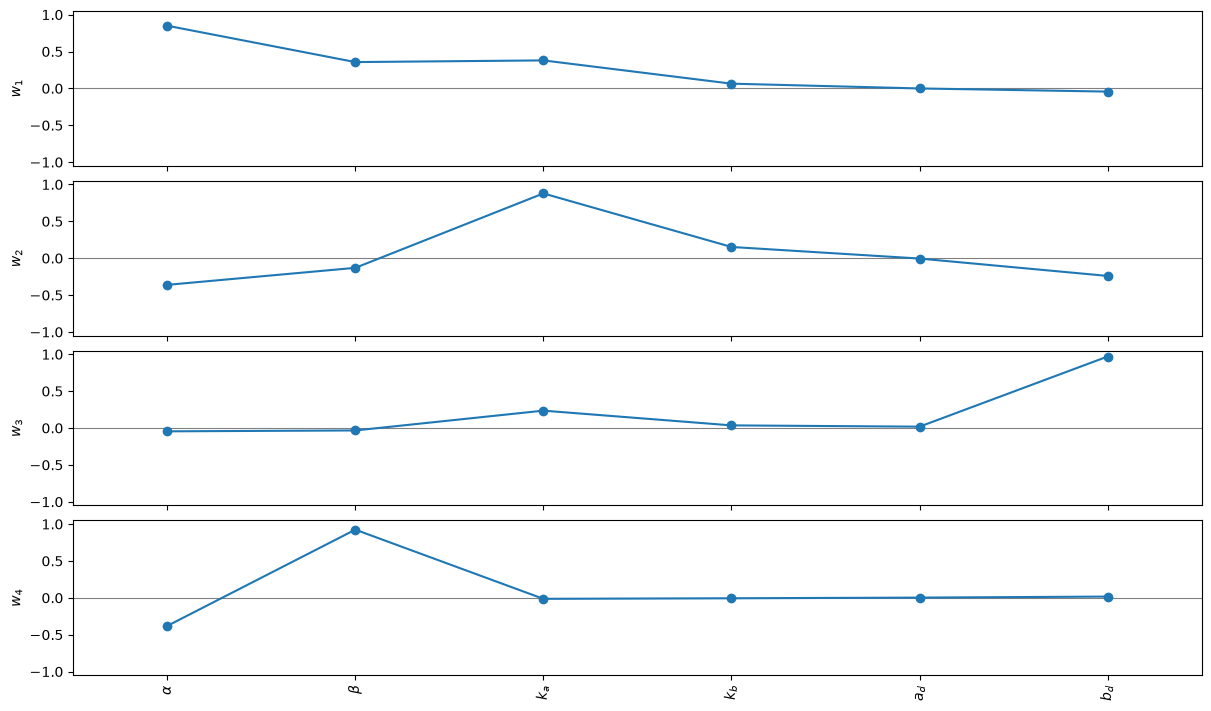

In [9]:
W = sub.W
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1, 2, 3], labels=labels, figsize=(12, 7))
plt.close(fig)
for k in range(6):
    print(f'w{k + 1}:', ', '.join(f'{n} {w:+.3f}' for n, w in zip(lm.NAMES, W[:, k])))
act = (W[:, :3]**2*lam[:3]).sum(axis=1)
print('activity scores (n = 3):', ', '.join(f'{n} {a:.3g}' for n, a in zip(lm.NAMES, act)),
      f'; share of alpha, ka, bd: {act[[0, 2, 5]].sum()/act.sum():.3f}')
# alpha and beta enter the near-wake length (Eq. 1) through 4 alpha I + 2 beta (1 - sqrt(1 - C_T));
# its gradient in normalized (alpha, beta), for C_T = 0.86 (8 m/s) and two rotor TIs:
c = 1 - np.sqrt(1 - 0.86)
for I in (0.06, 0.12):
    v = np.array([4*I*half[0], 2*c*half[1]])
    print(f'I = {I}: |cos| between w4 and the (alpha, beta) gradient of the near-wake denominator '
          f'{abs(W[:2, 3] @ v)/np.linalg.norm(v)/np.linalg.norm(W[:2, 3]):.2f}')
fig

The first eigenvector is led by the near-wake parameter $\alpha$ (0.850), with $k_a$ (0.380) and $\beta$ (0.357) of the same sign: everything that shortens the near wake or widens the wake raises the farm power. The second is led by $k_a$ (0.878) against $\alpha$ ($-0.361$), and the third is almost $b_d$ alone (0.969). The inactive directions are $\mathbf w_4$, a contrast of $\beta$ (0.924) and $\alpha$ ($-0.381$); $\mathbf w_5$, almost $k_b$ (0.980); and $\mathbf w_6$, almost $a_d$ (0.994). $\alpha$ and $\beta$ enter the near-wake length (Eq. 1) only through $4\alpha I + 2\beta(1-\sqrt{1-C_T})$, and $\mathbf w_4$ is nearly orthogonal to the direction that changes it (cosine 0.17 at the ambient TI 0.06 and 0.09 at TI 0.12, both at $C_T = 0.86$), so moving along $\mathbf w_4$ hardly changes the near wake. $a_d$ is inactive because FLORIS adds it in metres (at most 1 m of deflection), and $k_b$ because its range (0 to 0.02) is small next to $k_a I$. The activity scores ($n = 3$) put 91.7 % of the total on $\alpha$, $k_a$ and $b_d$.

y1 range [-1.31, 1.39]; corr(f, y1) = 0.682


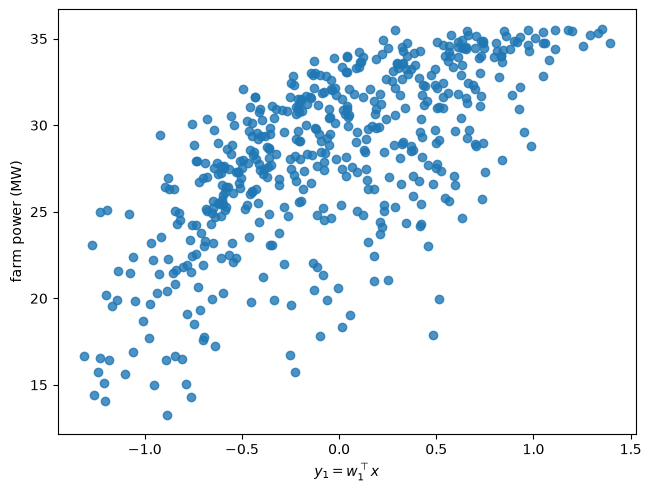

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label='farm power (MW)')
plt.close(fig)
xn = space.to_normalized(X)
y = xn @ W[:, :2]
print(f'y1 range [{y[:, 0].min():.2f}, {y[:, 0].max():.2f}]; corr(f, y1) = {np.corrcoef(f, y[:, 0])[0, 1]:.3f}')
fig

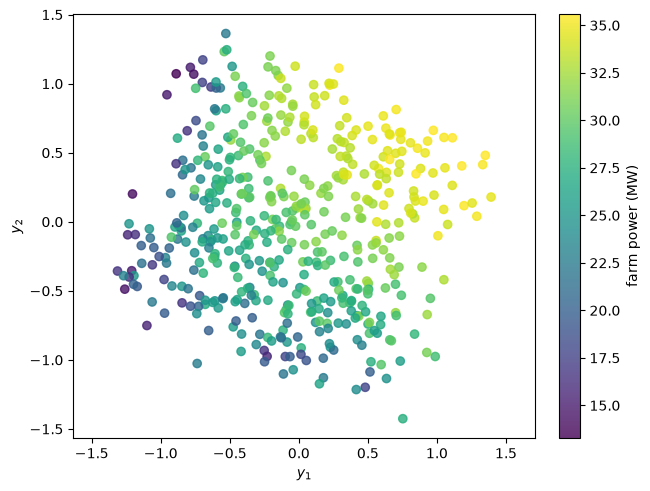

In [11]:
fig, ax = ac.plotting.plot_sufficient_summary(ac.with_dimension(sub, 2), X=X, f=f, dims=2,
                                              qoi_label='farm power (MW)')
plt.close(fig)
fig

corr(y3, normalized bd) = 0.970; mean P for |bd| < 0.02: 26.55 MW, for |bd| > 0.08: 30.07 MW


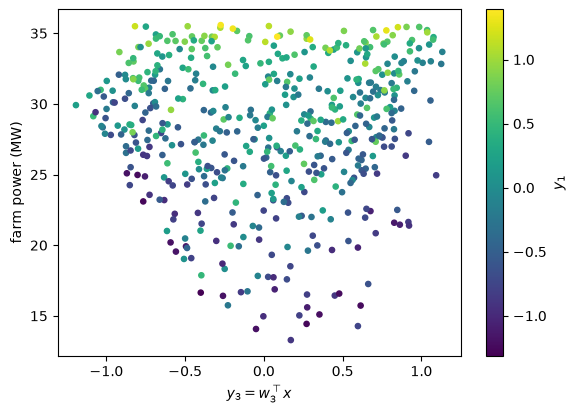

In [12]:
y3 = xn @ W[:, 2]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sc = ax.scatter(y3, f, c=y[:, 0], s=14, cmap='viridis')
fig.colorbar(sc, ax=ax, label=r'$y_1$')
ax.set_xlabel(r'$y_3 = w_3^\top x$'); ax.set_ylabel('farm power (MW)')
plt.close(fig)
print(f'corr(y3, normalized bd) = {np.corrcoef(y3, xn[:, 5])[0, 1]:.3f}; mean P for |bd| < 0.02: '
      f'{f[np.abs(X[:, 5]) < 0.02].mean():.2f} MW, for |bd| > 0.08: {f[np.abs(X[:, 5]) > 0.08].mean():.2f} MW')
fig

The farm power ranges over [13.29, 35.58] MW. Against the first active variable alone (first plot) it rises, but with wide scatter (correlation 0.682): one variable is not enough. In the plane of the first two (second plot) the power grows towards large $y_1$ and $y_2$, and the remaining spread comes from $y_3$. The third plot shows that dependence: $y_3$ is almost the normalized $b_d$ (correlation 0.970), and the power is lowest near $y_3 = 0$ and rises for deflection either way, because a deflected wake misses the turbine 4.8 D behind (mean 26.55 MW for $|b_d| < 0.02$, 30.07 MW for $|b_d| > 0.08$). This even, V-shaped dependence is what a gradient-based subspace sees but a linear fit would miss. The scatter also includes the small jumps of FLORIS's discrete choices (`DATA.md`, "Smoothness").

#### Surrogates on the active variables

We fit polynomials in one, two and three active variables and report the leave-one-out $R^2$.

polynomial of degree 3 in 1 active variable(s): LOO R^2 = 0.4915
polynomial of degree 3 in 2 active variable(s): LOO R^2 = 0.8191
polynomial of degree 2 in 3 active variable(s): LOO R^2 = 0.9032
polynomial of degree 3 in 3 active variable(s): LOO R^2 = 0.9754
polynomial of degree 4 in 3 active variable(s): LOO R^2 = 0.9899


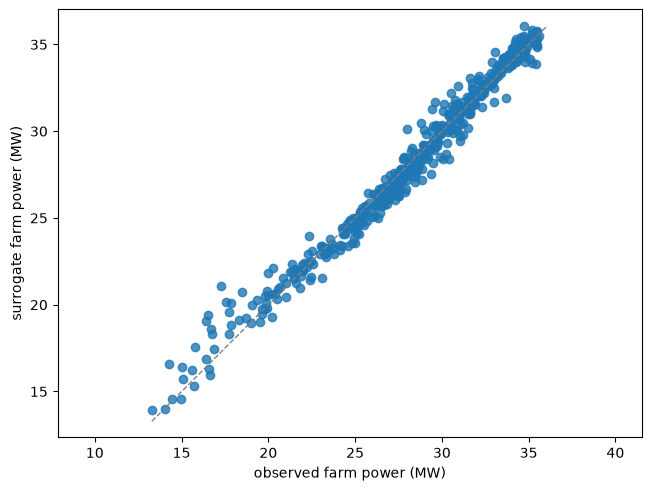

In [13]:
sur = {}
for n_, deg in [(1, 3), (2, 3), (3, 2), (3, 3), (3, 4)]:
    s_n = ac.with_dimension(sub, n_)
    sur[(n_, deg)] = ac.fit_surrogate(X=X, f=f, subspace=s_n, kind='poly', degree=deg)
    print(f'polynomial of degree {deg} in {n_} active variable(s): LOO R^2 = {sur[(n_, deg)].loo_r_squared:.4f}')
fig, ax = ac.plotting.plot_surrogate_fit(sur[(3, 3)], X=X, f=f, qoi_label='farm power (MW)')
plt.close(fig)
fig

One active variable explains about half of the variance (cubic, LOO $R^2 = 0.4915$) and two explain 0.8191, but three give 0.9754 with a cubic and 0.9899 with a quartic (the figure shows the cubic). A quadratic in three variables reaches only 0.9032, because the $b_d$ dependence is V-shaped rather than parabolic. So the six-parameter farm power is, to a few percent, a function of three linear combinations of the parameters.

#### Other turbine spacings

The paper reports Sobol indices per turbine spacing (Fig. 5). We repeat the analysis for the farm power at one alignment direction of each spacing in Table 1 (same samples, 200 bootstrap replicates), and plot two per-parameter measures against spacing: the share of $E[(\partial f/\partial x_i)^2]$ in normalized coordinates (the diagonal of $\mathbf C$ over its trace, a derivative-based sensitivity), and the first eigenvector, with its sign fixed so that its largest component is positive.

3.3D (120.0 deg): mean P 22.42 MW; lambda_k/lambda_k+1 = 2.56, 1.18, 191.50, 45.54; w1 = [+0.79, +0.29, +0.52, +0.08, -0.00, -0.15]; LOO R^2 (cubic, n = 3) 0.988


4.3D ( 42.0 deg): mean P 26.12 MW; lambda_k/lambda_k+1 = 2.54, 1.37, 153.64, 79.03; w1 = [+0.88, +0.32, +0.33, +0.05, -0.00, -0.06]; LOO R^2 (cubic, n = 3) 0.978
4.8D (180.0 deg): mean P 28.21 MW; lambda_k/lambda_k+1 = 2.42, 1.05, 156.13, 128.11; w1 = [+0.85, +0.36, +0.38, +0.06, -0.00, -0.04]; LOO R^2 (cubic, n = 3) 0.975


5.9D ( 75.0 deg): mean P 30.89 MW; lambda_k/lambda_k+1 = 2.19, 1.08, 961.31, 40.31; w1 = [+0.82, +0.40, +0.39, +0.07, -0.00, -0.01]; LOO R^2 (cubic, n = 3) 0.965


7.1D (156.0 deg): mean P 34.58 MW; lambda_k/lambda_k+1 = 1.98, 1.65, 117.00, 383.15; w1 = [+0.84, +0.38, +0.38, +0.07, -0.00, -0.04]; LOO R^2 (cubic, n = 3) 0.929
8.6D ( 90.0 deg): mean P 35.62 MW; lambda_k/lambda_k+1 = 1.70, 3.78, 98.22, 379.91; w1 = [+0.84, +0.39, +0.38, +0.07, -0.00, -0.01]; LOO R^2 (cubic, n = 3) 0.896


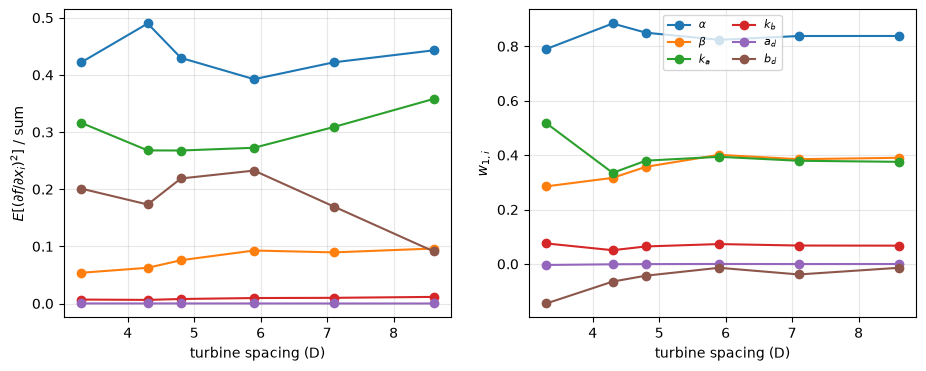

In [14]:
rows_out = []
W1s, shares = [], []
for kd, (wd, sp) in enumerate(zip(lm.DIRECTIONS, lm.SPACINGS)):
    s_d = ac.active_subspace(space=space, X=X, f=F[:, kd], grads=G[:, kd, :], estimator='as',
                             nboot=200, rng=SEED)
    l_d = s_d.eigenvalues
    w = s_d.W[:, 0]*np.sign(s_d.W[np.argmax(np.abs(s_d.W[:, 0])), 0])
    W1s.append(w)
    Gn = G[:, kd, :]*half                                  # gradients in normalized coordinates
    nu = np.mean(Gn**2, axis=0)
    shares.append(nu/nu.sum())
    r2 = ac.fit_surrogate(X=X, f=F[:, kd], subspace=ac.with_dimension(s_d, 3), kind='poly', degree=3).loo_r_squared
    print(f'{sp:3.1f}D ({wd:5.1f} deg): mean P {F[:, kd].mean():5.2f} MW; lambda_k/lambda_k+1 = '
          + ', '.join(f'{v:.2f}' for v in l_d[:4]/l_d[1:5]) + '; w1 = [' + ', '.join(f'{v:+.2f}' for v in w)
          + f']; LOO R^2 (cubic, n = 3) {r2:.3f}')
W1s, shares = np.array(W1s), np.array(shares)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for j in range(6):
    axes[0].plot(lm.SPACINGS, shares[:, j], 'o-', label=labels[j])
    axes[1].plot(lm.SPACINGS, W1s[:, j], 'o-', label=labels[j])
axes[0].set_ylabel(r'$E[(\partial f/\partial x_i)^2]$ / sum'); axes[1].set_ylabel(r'$w_{1,i}$')
for a in axes:
    a.set_xlabel('turbine spacing (D)'); a.grid(alpha=.3)
axes[1].legend(ncol=2, fontsize=8)
plt.close(fig)
fig

At every spacing the gap is after the third eigenvalue ($\lambda_3/\lambda_4$ between 98.22 and 961.31), and $\lambda_1/\lambda_2$ stays between 1.70 and 2.56, so the three-dimensional structure is not special to 180°. The first eigenvector barely changes (its $\alpha$ component is 0.79–0.88), and the cubic in three active variables has LOO $R^2$ between 0.896 (8.6 D) and 0.988 (3.3 D). The share of $b_d$ is 0.17–0.23 up to 7.1 D and drops to 0.09 at 8.6 D; the share of $k_a$ is 0.27–0.32 up to 7.1 D and 0.36 at 8.6 D; the share of $\alpha$ stays between 0.39 and 0.49.

### Comparison with the paper

The paper gives Sobol indices of the annual energy production (over a confidential wind rose, with its empirical power curve and TI map), in bar charts without numbers; the notebook has single flow cases with a generic set-up and derivative-based measures. So the comparison is qualitative. The cell computes the notebook's values.

In [15]:
rows = [
    ('dominant parameters at 4.8D (Fig. 4)', 'ka, bd, alpha (~79% of variance)',
     f'shares of E[grad^2]: ka {shares[k180, 2]:.2f}, bd {shares[k180, 5]:.2f}, alpha {shares[k180, 0]:.2f} '
     f'(sum {shares[k180, [0, 2, 5]].sum():.2f})'),
    ('ad at 4.8D', 'negligible', f'share {shares[k180, 4]:.1e}'),
    ('ka with spacing (Fig. 5a)', 'increases', ' -> '.join(f'{v:.2f}' for v in shares[:, 2])),
    ('alpha with spacing (Fig. 5c)', 'decreases', ' -> '.join(f'{v:.2f}' for v in shares[:, 0])),
    ('bd with spacing (Fig. 5f)', 'decreases', ' -> '.join(f'{v:.2f}' for v in shares[:, 5])),
    ('active subspace at 4.8D', 'not reported', f'n = 3, lambda3/lambda4 = {lam[2]/lam[3]:.0f}; '
     f'cubic LOO R^2 {sur[(3, 3)].loo_r_squared:.3f}'),
]
for q, p, v in rows:
    print(f'{q:38s} | {p:34s} | {v}')

dominant parameters at 4.8D (Fig. 4)   | ka, bd, alpha (~79% of variance)   | shares of E[grad^2]: ka 0.27, bd 0.22, alpha 0.43 (sum 0.92)
ad at 4.8D                             | negligible                         | share 8.0e-05
ka with spacing (Fig. 5a)              | increases                          | 0.32 -> 0.27 -> 0.27 -> 0.27 -> 0.31 -> 0.36
alpha with spacing (Fig. 5c)           | decreases                          | 0.42 -> 0.49 -> 0.43 -> 0.39 -> 0.42 -> 0.44
bd with spacing (Fig. 5f)              | decreases                          | 0.20 -> 0.17 -> 0.22 -> 0.23 -> 0.17 -> 0.09
active subspace at 4.8D                | not reported                       | n = 3, lambda3/lambda4 = 156; cubic LOO R^2 0.975


| Quantity | Paper value | Notebook value |
|---|---|---|
| Dominant parameters at 4.8 D | $k_a$, $b_d$ and to some degree $\alpha$, about 79 % of the variance of AEP [1, Fig. 4, p. 10] | $\alpha$ 0.43, $k_a$ 0.27, $b_d$ 0.22 of $E[\lVert\nabla f\rVert^2]$ (sum 0.92) at 180° |
| $a_d$ at 4.8 D | negligible, set to 0 afterwards [1, p. 10] | share $8.0\times10^{-5}$; $\mathbf w_6 \approx a_d$; FLORIS adds $a_d$ in metres |
| Parameter interactions | total-order indices well above first-order [1, p. 10] | three active directions, each mixing several parameters; $b_d$ enters through a V-shaped (even) dependence |
| $k_a$ with spacing 3.3 → 8.6 D | increases [1, Fig. 5a] | 0.32, 0.27, 0.27, 0.27, 0.31, 0.36 (rises only beyond 5.9 D) |
| $\alpha$ with spacing | decreases [1, Fig. 5c] | 0.42, 0.49, 0.43, 0.39, 0.42, 0.44 (no trend) |
| $b_d$ with spacing | decreases [1, Fig. 5f] | 0.20, 0.17, 0.22, 0.23, 0.17, 0.09 (drops at 8.6 D) |
| Active subspace at 4.8 D | not reported | $n = 3$, $\lambda_3/\lambda_4 = 156$; cubic LOO $R^2 = 0.975$ |

The notebook agrees with the paper on which parameters matter at 4.8 D ($\alpha$, $k_a$, $b_d$) and on $a_d$, which we can now explain by its units in FLORIS. The spacing trends of Fig. 5 are reproduced only in part ($b_d$ falls and $k_a$ rises at the largest spacing; $\alpha$ shows no trend). The differences are expected: the paper's output is AEP over all wind speeds and the directions of its wind rose, with an empirical power curve and measured TI, while ours is the power at 8 m/s and one direction per spacing with FLORIS's example TI and shear; and Sobol indices of a variance and derivative-based shares are different measures.

### References

[1] M. T. van Beek, A. Viré, and S. J. Andersen. [Sensitivity and uncertainty of the FLORIS model applied on the Lillgrund wind farm](https://doi.org/10.3390/en14051293). *Energies*, 14(5):1293, 2021.

[2] NREL. FLORIS, version 2.0.1, 2020. https://github.com/NREL/floris (Apache-2.0); PyPI `floris==2.0.1`.

[3] M. Bastankhah and F. Porté-Agel. [Experimental and theoretical study of wind turbine wakes in yawed conditions](https://doi.org/10.1017/jfm.2016.595). *Journal of Fluid Mechanics*, 806:506–541, 2016.

[4] J. King, P. Fleming, R. King, L. A. Martínez-Tossas, C. J. Bay, R. Mudafort, and E. Simley. [Control-oriented model for secondary effects of wake steering](https://doi.org/10.5194/wes-6-701-2021). *Wind Energy Science*, 6(3):701–714, 2021.

[5] A. Crespo and J. Hernández. [Turbulence characteristics in wind-turbine wakes](https://doi.org/10.1016/0167-6105(95)00033-X). *Journal of Wind Engineering and Industrial Aerodynamics*, 61(1):71–85, 1996.

[6] DTU Wind Energy. PyWake, version 2.6.20, Lillgrund example (`py_wake/examples/data/lillgrund.py`, MIT). https://gitlab.windenergy.dtu.dk/TOPFARM/PyWake

[7] J. Jeppsson, P. E. Larsen, and A. Larsson. *Technical Description Lillgrund Wind Power Plant*. Vattenfall, Stockholm, 2008 (the layout; cited by [1]).

[8] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[R1]: https://doi.org/10.3390/en14051293
[R2]: https://github.com/NREL/floris
[R3]: https://doi.org/10.1017/jfm.2016.595
[R4]: https://doi.org/10.5194/wes-6-701-2021
[R5]: https://doi.org/10.1016/0167-6105(95)00033-X
[R6]: https://gitlab.windenergy.dtu.dk/TOPFARM/PyWake

In [16]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 3.3 s
